In [1]:
%pip install -U numpy pandas matplotlib seaborn scipy scikit-learn xgboost lightgbm shap imbalanced-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
df = pd.read_csv(r"C:\Users\mithi\Downloads\brain_stroke.csv")

Exploring Dataset

In [3]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [4]:
df.tail()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4976,Male,41.0,0,0,No,Private,Rural,70.15,29.8,formerly smoked,0
4977,Male,40.0,0,0,Yes,Private,Urban,191.15,31.1,smokes,0
4978,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,31.8,smokes,0
4979,Male,40.0,0,0,Yes,Private,Rural,83.94,30.0,smokes,0
4980,Female,80.0,1,0,Yes,Private,Urban,83.75,29.1,never smoked,0


Check Shape of Dataset

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4981 entries, 0 to 4980
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4981 non-null   str    
 1   age                4981 non-null   float64
 2   hypertension       4981 non-null   int64  
 3   heart_disease      4981 non-null   int64  
 4   ever_married       4981 non-null   str    
 5   work_type          4981 non-null   str    
 6   Residence_type     4981 non-null   str    
 7   avg_glucose_level  4981 non-null   float64
 8   bmi                4981 non-null   float64
 9   smoking_status     4981 non-null   str    
 10  stroke             4981 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 579.7 KB


In [6]:
df.shape

(4981, 11)

Check if null values exists

In [7]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Check of unique values

In [8]:
df.nunique()

gender                  2
age                   104
hypertension            2
heart_disease           2
ever_married            2
work_type               4
Residence_type          2
avg_glucose_level    3895
bmi                   342
smoking_status          4
stroke                  2
dtype: int64

Check of all columns

In [9]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

Check unique values in respective columns

In [10]:
df_cat=df[['gender', 'hypertension', 'heart_disease', 'ever_married','work_type', 'Residence_type',
                 'smoking_status', 'stroke']]

In [11]:
for i in df_cat.columns:
    print(df_cat[i].unique())

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
[0 1]
[1 0]
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
<ArrowStringArray>
['Private', 'Self-employed', 'Govt_job', 'children']
Length: 4, dtype: str
<ArrowStringArray>
['Urban', 'Rural']
Length: 2, dtype: str
<ArrowStringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str
[1 0]


In [12]:
for i in df_cat.columns:
    print(df_cat[i].value_counts())

gender
Female    2907
Male      2074
Name: count, dtype: int64
hypertension
0    4502
1     479
Name: count, dtype: int64
heart_disease
0    4706
1     275
Name: count, dtype: int64
ever_married
Yes    3280
No     1701
Name: count, dtype: int64
work_type
Private          2860
Self-employed     804
children          673
Govt_job          644
Name: count, dtype: int64
Residence_type
Urban    2532
Rural    2449
Name: count, dtype: int64
smoking_status
never smoked       1838
Unknown            1500
formerly smoked     867
smokes              776
Name: count, dtype: int64
stroke
0    4733
1     248
Name: count, dtype: int64


Visualization of unique values using graphs/

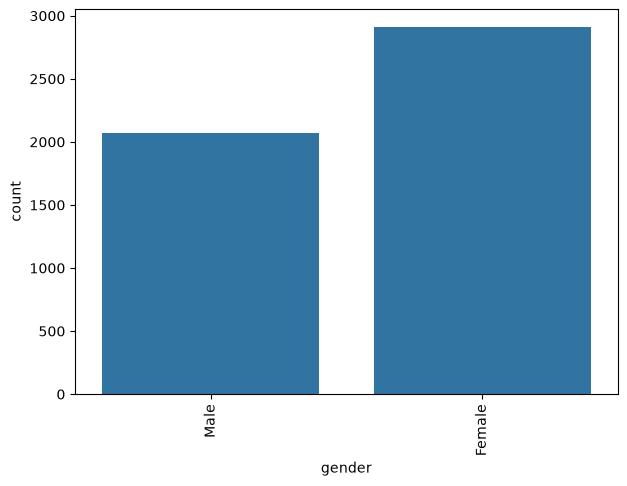

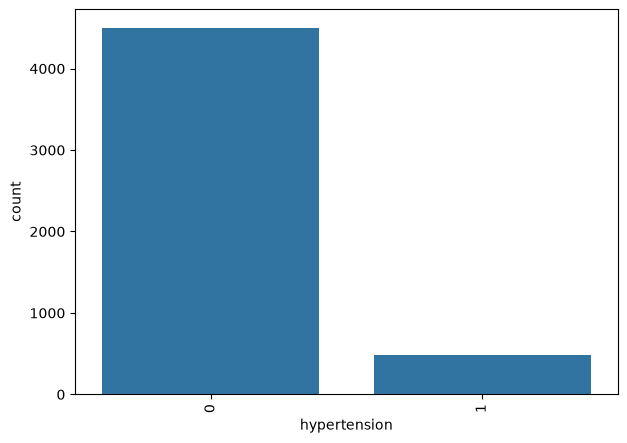

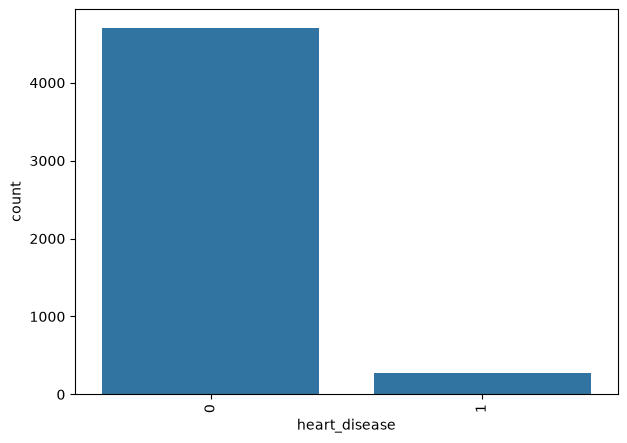

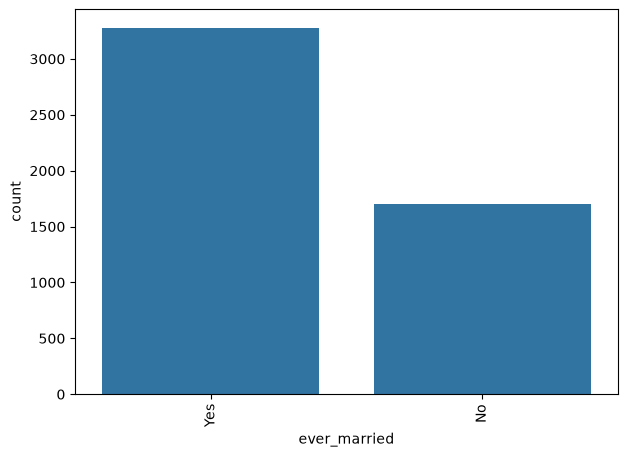

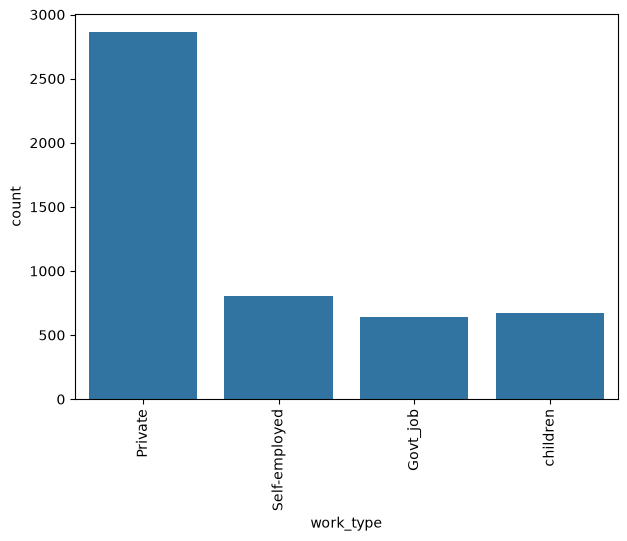

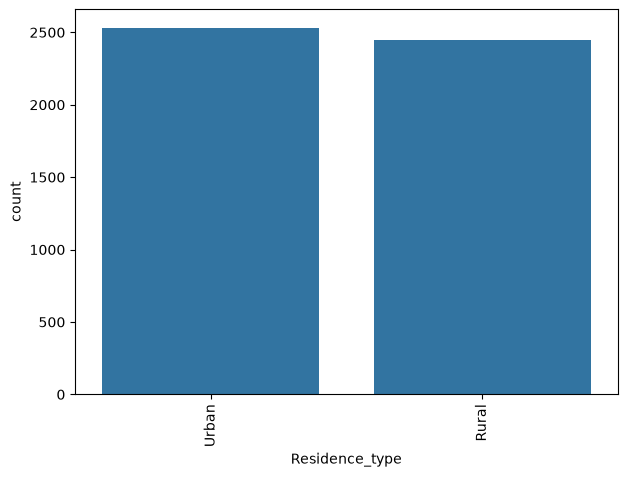

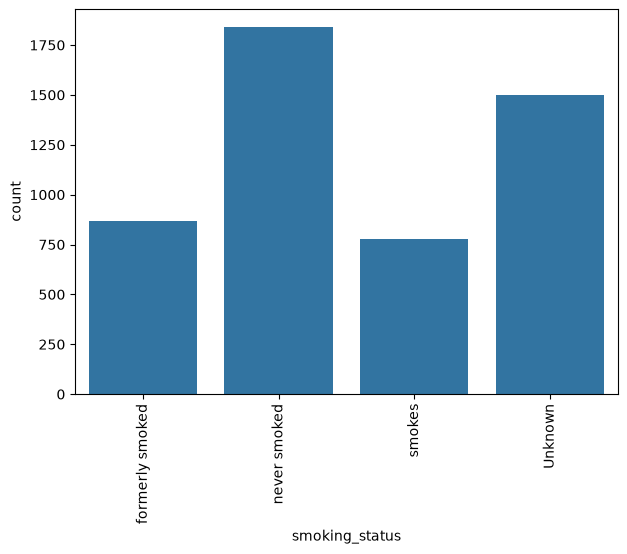

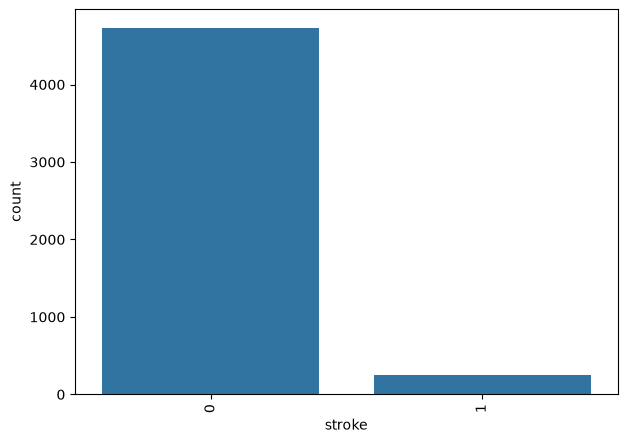

In [13]:
for i in df_cat.columns:
    plt.figure(figsize = (7,5))
    sns.countplot(x=df_cat[i])
    plt.xticks(rotation = 90)
    plt.show()

There is an oversampling in the dataset. There is a big difference between those who do not have a stroke and those who do.

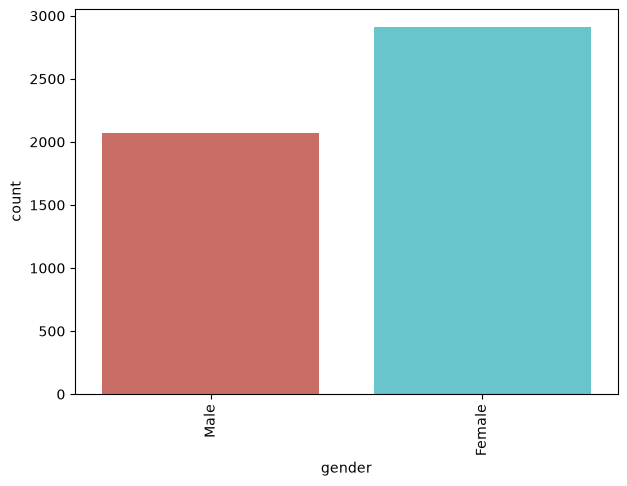

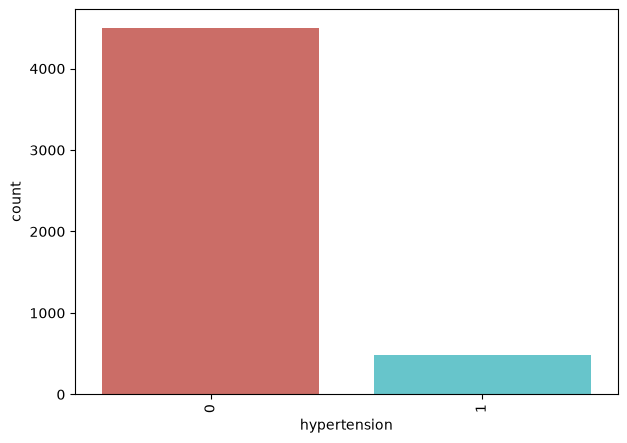

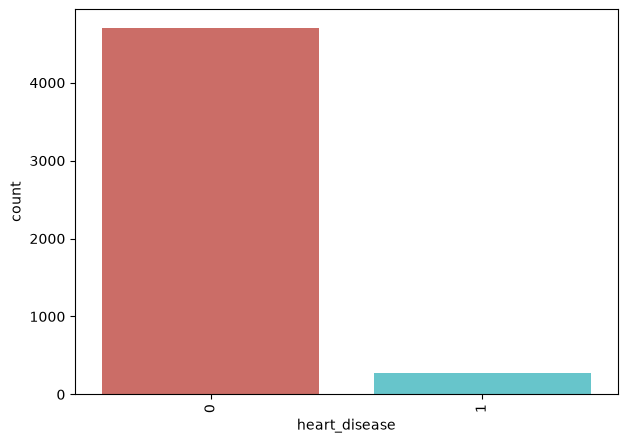

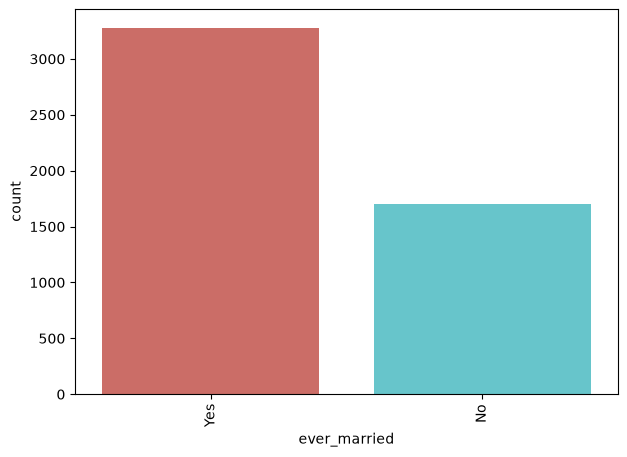

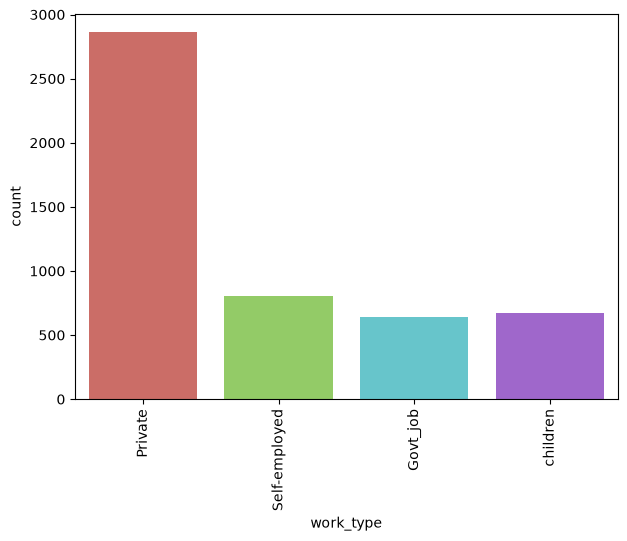

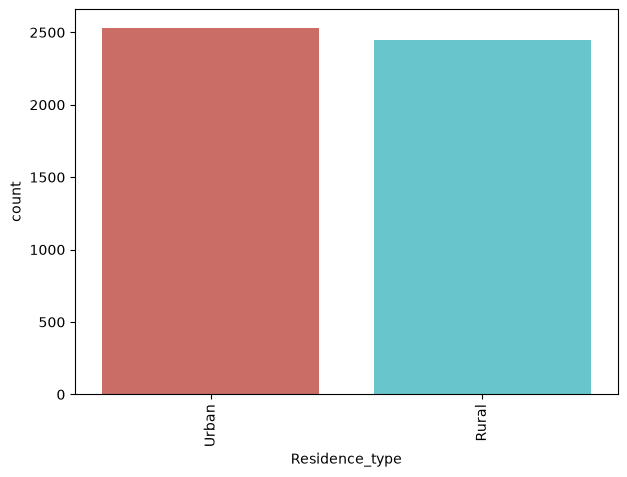

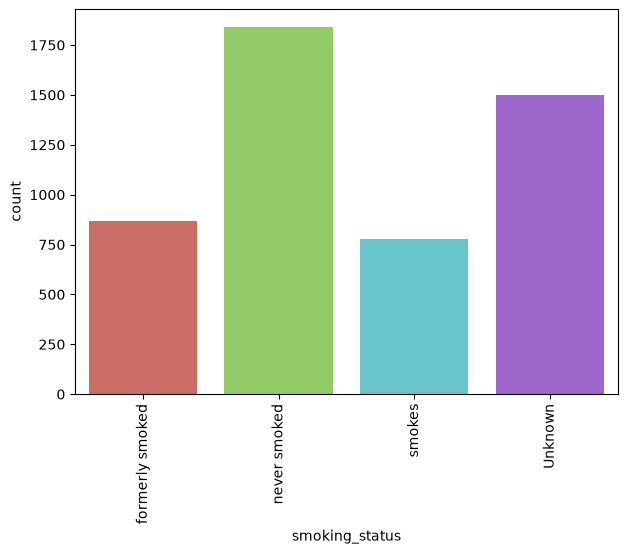

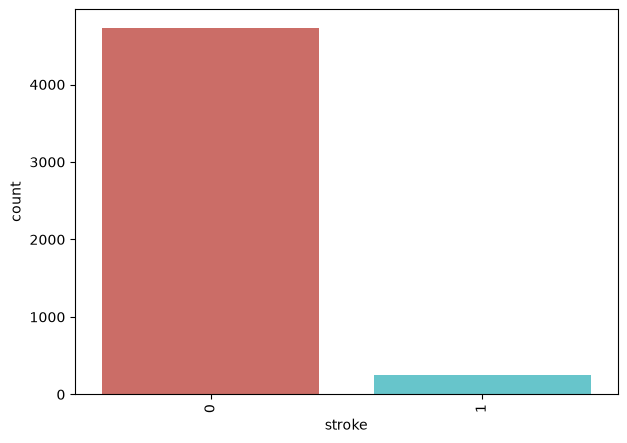

In [14]:
for i in df_cat.columns:
    plt.figure(figsize=(7,5))
    sns.countplot(x=i, data=df_cat, hue=i, palette='hls', legend=False)
    plt.xticks(rotation=90)
    plt.show()

In [15]:
df_num = df[['age', 'avg_glucose_level', 'bmi']]

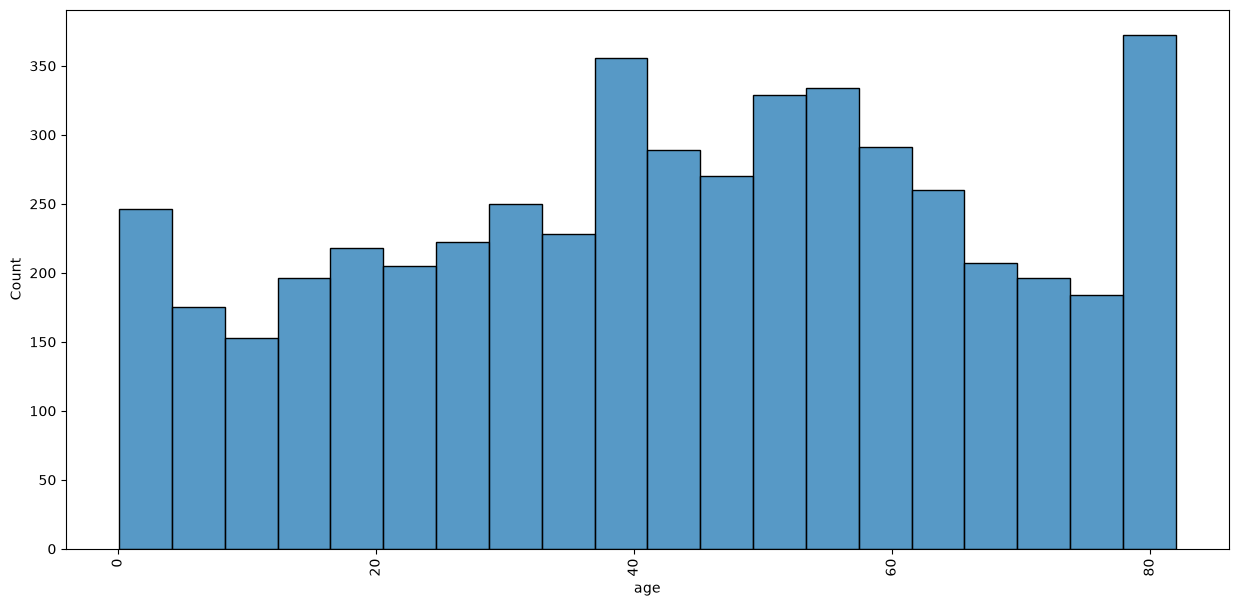

In [16]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['age'])
plt.xticks(rotation = 90)
plt.show()

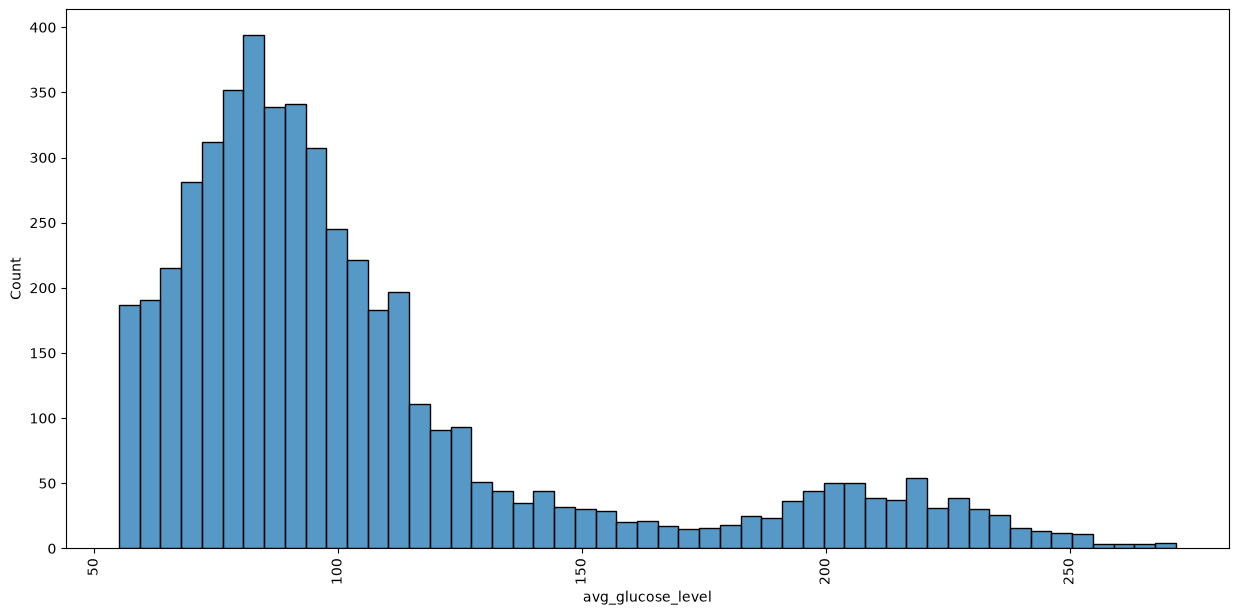

In [17]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['avg_glucose_level'])
plt.xticks(rotation = 90)
plt.show()

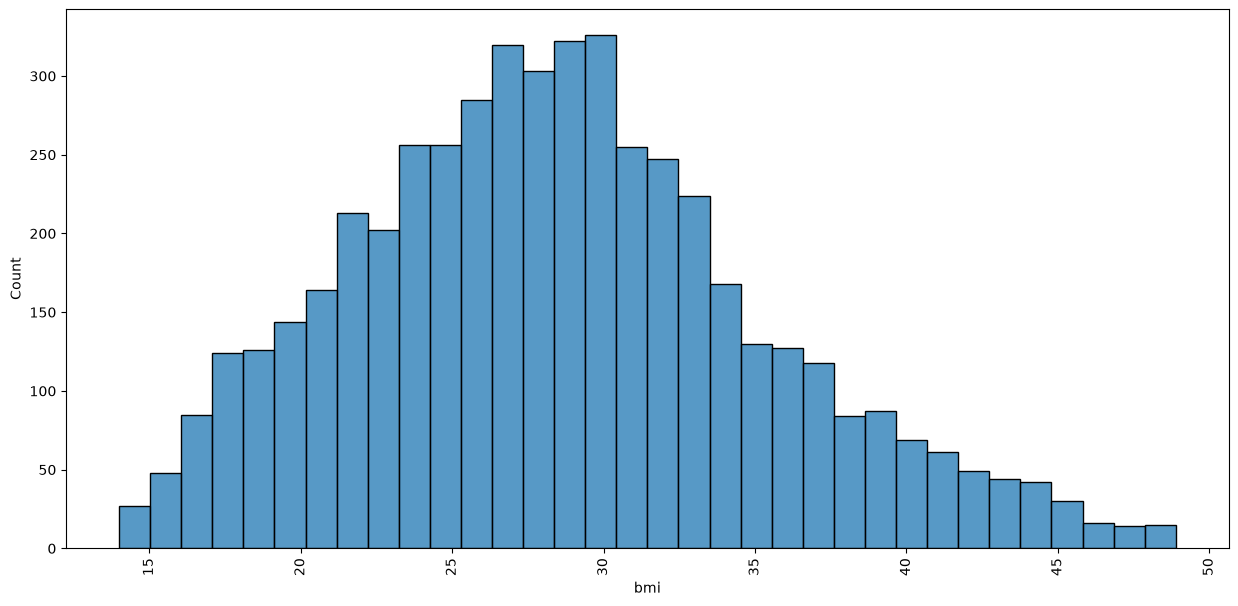

In [18]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['bmi'])
plt.xticks(rotation = 90)
plt.show()

Transforming categorical column using encoding

In [19]:
df['ever_married'] = [ 0 if i !='Yes' else 1 for i in df['ever_married'] ]
df['gender'] = [0 if i != 'Female' else 1 for i in df['gender']]

In [20]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,Private,Urban,228.69,36.6,formerly smoked,1
1,0,80.0,0,1,1,Private,Rural,105.92,32.5,never smoked,1
2,1,49.0,0,0,1,Private,Urban,171.23,34.4,smokes,1
3,1,79.0,1,0,1,Self-employed,Rural,174.12,24.0,never smoked,1
4,0,81.0,0,0,1,Private,Urban,186.21,29.0,formerly smoked,1


In [21]:
df=pd.get_dummies(df,columns=['work_type','Residence_type','smoking_status'])

In [22]:
df.sample(10)

,gender,age,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
15,1,60.0,0,0,0,89.22,37.8,1,False,True,False,False,False,True,False,False,True,False
2114,0,23.0,0,0,0,77.75,38.8,0,False,True,False,False,False,True,False,False,False,True
1245,1,40.0,0,0,0,78.04,32.4,0,False,True,False,False,False,True,False,False,False,True
3744,1,58.0,0,0,1,81.96,34.6,0,False,False,True,False,True,False,False,False,True,False
182,0,79.0,0,0,1,72.73,28.4,1,False,True,False,False,True,False,False,False,True,False
1368,0,2.0,0,0,0,111.02,20.5,0,False,False,False,True,True,False,True,False,False,False
1692,0,64.0,0,0,1,187.87,32.3,0,True,False,False,False,True,False,False,False,True,False
1158,0,63.0,0,0,1,78.43,18.8,0,False,False,True,False,True,False,False,False,True,False
4353,1,33.0,0,0,1,88.17,38.6,0,False,True,False,False,True,False,False,True,False,False
2293,0,8.0,0,0,0,90.26,18.1,0,False,False,False,True,True,False,True,False,False,False


split the dataset using train test split

In [23]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

In [24]:
X = df.drop(['stroke'], axis=1)
y = df['stroke']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [26]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [27]:
# smote = SMOTE(sampling_strategy=1.0,random_state=42,k_neighbors=5)

# X_train_smote, y_train_smote = smote.fit_resample(X_train,y_train)

In [28]:
# print("Before SMOTE:")
# print(y_train.value_counts())

# print("After SMOTE:")
# print(y_train_smote.value_counts())

In [29]:
X.shape

(4981, 17)

In [30]:
y.shape

(4981,)

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

Logistic Regression

In [32]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

lr_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10] # Regularization strength
}

lr_grid = GridSearchCV(lr_pipeline, param_grid=lr_param_grid, cv=skf, scoring='recall', n_jobs=-1)
lr_grid.fit(X_train, y_train)

lr_pred = lr_grid.predict(X_test)
lr_prob = lr_grid.predict_proba(X_test)[:, 1]

print("Best LR Parameters:", lr_grid.best_params_)

Best LR Parameters: {'classifier__C': 0.1}


In [33]:
from sklearn.metrics import confusion_matrix

In [34]:
cm=confusion_matrix(y_test, lr_pred)

In [35]:
print(cm)

[[710 237]
 [  8  42]]


In [36]:
from sklearn.metrics import classification_report, roc_auc_score

lr_prob = lr_grid.predict_proba(X_test)[:, 1]

print("--- Logistic Regression Performance ---")
print(classification_report(y_test, lr_pred, target_names=['No Stroke', 'Stroke']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_prob):.4f}")

--- Logistic Regression Performance ---
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       947
      Stroke       0.15      0.84      0.26        50

    accuracy                           0.75       997
   macro avg       0.57      0.79      0.55       997
weighted avg       0.95      0.75      0.82       997

ROC-AUC Score: 0.8405


In [37]:
from sklearn import metrics

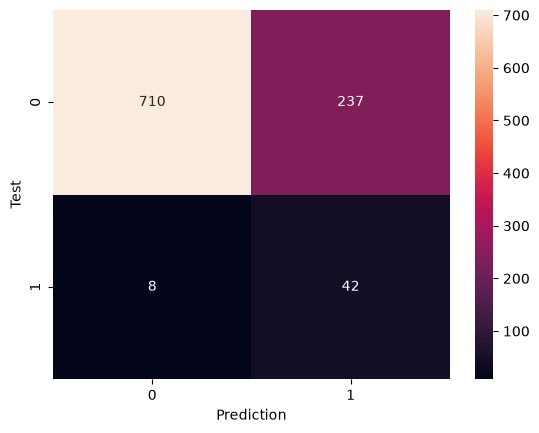

In [38]:
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

-- True Negatives (Actual 0, Predicted 0): The model correctly predicted class 0 a total of 710 times.   
-- False Positives (Actual 0, Predicted 1): The model incorrectly predicted class 1 237 times.   
-- False Negatives (Actual 1, Predicted 0): The model incorrectly predicted class 0 when the actual class was 1 a total of 8 times.   
-- True Positives (Actual 1, Predicted 1): The model correctly predicted class 1 42 times.   

Decision Tree

In [39]:
dt_pipeline = Pipeline([
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

dt_param_grid = {
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(dt_pipeline, param_grid=dt_param_grid, cv=skf, scoring='recall', n_jobs=-1)
dt_grid.fit(X_train, y_train)

dt_pred = dt_grid.predict(X_test)
dt_prob = dt_grid.predict_proba(X_test)[:, 1]

print("Best DT Parameters:", dt_grid.best_params_)

Best DT Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_split': 10}


In [40]:
cm=confusion_matrix(y_test,dt_pred)
cm

array([[662, 285],
       [ 12,  38]])

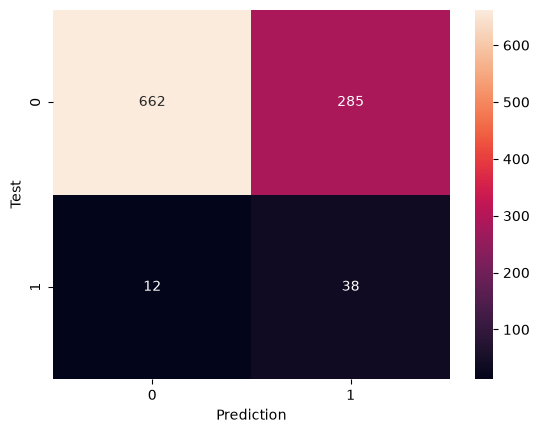

In [41]:
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

Random Forest

In [42]:
rf_pipeline = Pipeline([
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, 15],
    'classifier__min_samples_leaf': [1, 2, 4]
}

rf_grid = GridSearchCV(rf_pipeline, param_grid=rf_param_grid, cv=skf, scoring='recall', n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_pred = rf_grid.predict(X_test)
rf_prob = rf_grid.predict_proba(X_test)[:, 1]

print("Best RF Parameters:", rf_grid.best_params_)

Best RF Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 50}


In [43]:
cm = confusion_matrix(y_test, rf_pred)
cm

array([[683, 264],
       [  8,  42]])

In [44]:
rf_pred = rf_grid.predict(X_test)
rf_prob = rf_grid.predict_proba(X_test)[:, 1]
custom_threshold = 0.25
rf_pred_tuned = (rf_prob >= custom_threshold).astype(int)

print("--- Random Forest Performance ---")
print(classification_report(y_test, rf_pred_tuned, target_names=['No Stroke', 'Stroke']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_prob):.4f}")

--- Random Forest Performance ---
              precision    recall  f1-score   support

   No Stroke       0.99      0.52      0.68       947
      Stroke       0.09      0.94      0.17        50

    accuracy                           0.54       997
   macro avg       0.54      0.73      0.42       997
weighted avg       0.95      0.54      0.65       997

ROC-AUC Score: 0.8293


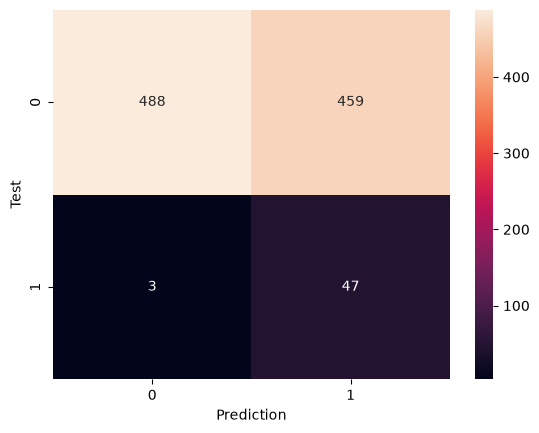

In [45]:
from sklearn.metrics import recall_score, roc_auc_score, precision_score, f1_score

sns.heatmap(confusion_matrix(y_test, rf_pred_tuned), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

In [46]:
models = {
    'Logistic Regression': (lr_pred, lr_prob),
    'Decision Tree': (dt_pred, dt_prob),
    'Random Forest': (rf_pred, rf_prob)
}
comparison_data = []

for name, (preds, probs) in models.items():
    comparison_data.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, probs),
        'Stroke Recall': recall_score(y_test, preds, pos_label=1),
        'Stroke Precision': precision_score(y_test, preds, pos_label=1, zero_division=0),
        'Stroke F1-Score': f1_score(y_test, preds, pos_label=1)
    })

In [47]:
comparison_df = pd.DataFrame(comparison_data).set_index('Model')
display(comparison_df)

,ROC-AUC,Stroke Recall,Stroke Precision,Stroke F1-Score
Model,,,,
Logistic Regression,0.840486,0.84,0.150538,0.255319
Decision Tree,0.783115,0.76,0.117647,0.203753
Random Forest,0.829293,0.84,0.137255,0.235955


In [48]:
import shutil
import os

print("Model file exists:", os.path.exists("stroke_model.joblib"))
print("Saved at:", os.path.abspath("stroke_model.joblib"))

Model file exists: True
Saved at: C:\Users\mithi\stroke_model.joblib


In [49]:

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

os.makedirs("assets", exist_ok=True)

trained_models = {
    "Logistic Regression": lr_grid,     
    "Decision Tree": dt_grid,          
    "Random Forest": rf_grid,           
}
RF_NAME = "Random Forest"
DF = df  

row = []
rows = []
for name, m in trained_models.items():
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 4),
    })
metrics_df = pd.DataFrame(rows)
metrics_df.to_csv("assets/metrics_comparison.csv", index=False)
print(metrics_df)

counts = DF["stroke"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(["No stroke (0)", "Stroke (1)"], counts.values, color=["#0f766e", "#b45309"])
plt.ylabel("Records")
plt.title("Class distribution")
plt.tight_layout()
plt.savefig("assets/class_distribution.png", dpi=150)
plt.close()

plt.figure(figsize=(6, 4))
plt.hist(DF.loc[DF["stroke"] == 0, "age"], bins=20, alpha=0.6, label="No stroke (0)", color="#0f766e")
plt.hist(DF.loc[DF["stroke"] == 1, "age"], bins=20, alpha=0.8, label="Stroke (1)", color="#b45309")
plt.xlabel("Age")
plt.ylabel("Records")
plt.title("Age distribution by class")
plt.legend()
plt.tight_layout()
plt.savefig("assets/age_by_stroke.png", dpi=150)
plt.close()

n = len(trained_models)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
for ax, (name, m) in zip(np.atleast_1d(axes), trained_models.items()):
    pred = (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("assets/confusion_matrices.png", dpi=150)
plt.close()

plt.figure(figsize=(6, 5))
for name, m in trained_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.tight_layout()
plt.savefig("assets/roc_curves.png", dpi=150)
plt.close()


                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7543     0.1505    0.84  0.2553   0.8405
1        Decision Tree    0.7021     0.1176    0.76  0.2038   0.7831
2        Random Forest    0.7272     0.1373    0.84  0.2360   0.8293


In [53]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
from importlib.metadata import version
from sklearn.pipeline import Pipeline

import os
import platform
import tempfile
import joblib
import numpy as np

PROJECT_DIR = Path(r"C:\New folder (2)")

In [54]:
artifact = joblib.load(
    PROJECT_DIR / "model_exports" / "stroke_rf.joblib"
)

# Pass raw inputs—the saved pipeline handles preprocessing.
patients = pd.read_csv(
    PROJECT_DIR / "brain_stroke.csv"
).drop(columns="stroke").head(5)

positive_index = artifact["classes"].index(
    artifact["positive_class"]
)

probabilities = artifact["model"].predict_proba(
    patients
)[:, positive_index]

predictions = (
    probabilities >= artifact["threshold"]
).astype(int)

display(pd.DataFrame({
    "Stroke probability": probabilities,
    "Predicted class": predictions,
}, index=patients.index))

print("Model loaded successfully.")
print("Threshold:", artifact["threshold"])

,Stroke probability,Predicted class
0,0.824682,1
1,0.695438,1
2,0.605898,1
3,0.830144,1
4,0.821391,1


Model loaded successfully.
Threshold: 0.25


In [55]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

PROJECT_DIR = Path(r"C:\New folder (2)")
ASSETS_DIR = PROJECT_DIR / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

positive_index = list(rf_grid.classes_).index(1)
probabilities = rf_grid.predict_proba(X_test)[:, positive_index]

threshold_values = sorted(set(
    np.round(np.arange(0.05, 1.0, 0.05), 2).tolist()
    + [float(custom_threshold)]
))

rows = []

for threshold in threshold_values:
    predictions = (probabilities >= threshold).astype(int)

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Positives": int(
            ((predictions == 1) & (np.asarray(y_test) == 0)).sum()
        ),
    })

threshold_results = pd.DataFrame(rows)
output_path = ASSETS_DIR / "threshold_results.csv"
threshold_results.to_csv(output_path, index=False)

display(threshold_results)
print("Saved:", output_path)

,Threshold,Precision,Recall,F1,False Positives
0,0.05,0.055432,1.00,0.105042,852
1,0.10,0.063371,1.00,0.119190,739
2,0.15,0.071429,0.98,0.133152,637
3,0.20,0.081911,0.96,0.150943,538
4,0.25,0.092885,0.94,0.169065,459
5,0.30,0.104308,0.92,0.187373,395
6,0.35,0.114144,0.92,0.203091,357
7,0.40,0.120968,0.90,0.213270,327
8,0.45,0.129683,0.90,0.226700,302
9,0.50,0.137255,0.84,0.235955,264


Saved: C:\New folder (2)\assets\threshold_results.csv
